# Evals / LLM-as-a-Judge — From Scratch

## 🏗️ Build | 🚢 Ship | 📤 Share

### 🏗️ Build

Build four judges for an EU AI Act assistant, validate their output, and find the answers where their scores disagree.

### 🚢 Ship

Run the same harness against your group project and keep an auditable JSONL record of the answers, scores, rationales, and model versions.

### 📤 Share

Bring one disagreement case. Explain what each judge measured and which evidence you used to decide whether the answer passed.

## Student mission brief

Your team has eight plausible-looking answers. Your job is to determine which are correct, useful, clear, and supported by the source—and to avoid treating one model score as ground truth.

> **Why this matters to you as an Towerbrook consultant:** A client needs to know what a score supports, how it was produced, and which outputs still require review. This notebook produces that audit trail instead of presenting a dashboard number without its underlying evidence.

## The assignment

You have eight answers from an EU AI Act assistant. Build an evaluator that can tell you more than “these look fine.”

By the end, you will have:

- an accuracy judge for questions with a known answer;
- rubric-based quality and clarity judges for open-ended answers;
- a groundedness judge that checks claims against the supplied source;
- a record of every answer, score, and rationale;
- a view of the cases where the judges disagree; and
- a small repeatability check showing why one score is not a permanent truth.

The useful question is not “Which judge is best?” It is “What evidence does this judge need, and what can its score actually support?”

**Estimated time:** 30–40 minutes


## Setup

Copy `.env.template` to `.env` at the repository root and configure either OpenAI, Anthropic, or an OpenAI-compatible endpoint. LiteLLM handles the chat calls.

`LLM_MODEL` selects the assistant under test. You may optionally set `JUDGE_MODEL` to evaluate with a different model; otherwise the notebook uses the same model for both roles and labels that limitation in the saved results.


In [1]:
import json
from pathlib import Path

import sys; sys.path.insert(0, "..")
from helpers.llm_call import chat, chat_stream, model_name, resolve
from helpers.display import stream_md
from helpers import ui

# Two models: one answers, one grades. Both are resolved by helpers/llm_call.py, which
# is the only file that knows where your models live — so this notebook reads the same
# whether you are on OpenAI, Azure, Bedrock, or a self-hosted server.
MODEL = model_name("chat")
JUDGE_MODEL = model_name("judge")

print(f"Assistant model: {MODEL}")
print(f"API endpoint:    {resolve('chat').base_url or 'provider default'}")
print(f"Judge model:     {JUDGE_MODEL}" + (" (same model)" if JUDGE_MODEL == MODEL else ""))

FACTSHEET = (Path("..") / "data" / "eu_ai_act_summary.md").read_text()
QUESTIONS = [json.loads(line) for line in Path("data/seed_questions.jsonl").read_text().splitlines() if line.strip()]
print(f"Loaded EU AI Act summary ({len(FACTSHEET)} chars) and {len(QUESTIONS)} questions.")


Assistant model: gpt-5-mini
API endpoint:    provider default
Judge model:     gpt-5-mini (same model)
Loaded EU AI Act summary (3909 chars) and 8 questions.


## Task 1 — Generate the answers we will evaluate

The assistant must answer from the supplied EU AI Act summary. We run it once and keep its answers fixed so every judge sees the same text.

The questions require different kinds of evidence:

| Type | Example | Evaluation evidence |
|---|---|---|
| **Factual** | “What is the maximum fine?” | A reviewed reference answer |
| **Explanatory** | “Explain the risk-based approach.” | A quality rubric and the source text |
| **Advisory** | “What should a client deploying hiring AI prioritise?” | A quality rubric and the source text |

An answer can be readable and still be wrong or unsupported. Keep that distinction in mind when the scores appear.


In [2]:
SYSTEM = ("Answer questions about the EU AI Act using only the summary below. "
          "If the summary does not support a claim, say so. Be concise.\n\n")


def ask(question: str, stream: bool = False) -> str:
    """Answer using only the EU AI Act summary."""
    if stream:
        return stream_md(chat_stream(question, system=SYSTEM + FACTSHEET,
                                     temperature=1.0)).strip()  #CHANGE
    return chat(question, system=SYSTEM + FACTSHEET, temperature=1.0)  #CHANGE

print(f"[{QUESTIONS[0]['id']} · {QUESTIONS[0]['type']}] {QUESTIONS[0]['question']}")
first = ask(QUESTIONS[0]["question"], stream=True)
runs = [{**QUESTIONS[0], "response": first}] + [
    {**q, "response": ask(q["question"], stream=True)} for q in QUESTIONS[1:]
]
print(f"\nAnswered {len(runs)} questions.")


[f01 · factual] What is the maximum administrative fine for engaging in a prohibited AI practice under the EU AI Act?


Up to €35 million or 7% of total worldwide annual turnover, whichever is higher (with a capped, lower figure for SMEs and start‑ups).

The prohibitions (the "unacceptable risk" measures in Article 5) take effect on 2 February 2025.

The summary doesn't specify a single supervisor for general-purpose models. Enforcement and oversight are shared between the new European AI Office, an AI Board, national competent authorities, and notified bodies.

No. The summary says the Act does not regulate AI used purely for military, defence, or national security purposes.

In plain terms, the EU AI Act sorts AI systems by how risky they are to people’s health, safety, or fundamental rights, and then applies rules that match that level of risk: higher risk → stricter duties.

- Four tiers:  
  - Unacceptable risk: a short list of banned practices (e.g., manipulative/deceptive techniques that cause harm; exploiting vulnerabilities like age or disability; social scoring by public authorities; untargeted scraping of faces to build recognition databases; emotion recognition in schools/work; real‑time remote biometric ID in public spaces except narrow law‑enforcement cases).  
  - High risk: allowed but heavily regulated (covers biometrics, critical infrastructure, education, employment/worker management, access to essential services, law enforcement, migration/border control, administration of justice).  
  - Limited risk: transparency duties — systems that interact with people or generate content must disclose it (chatbots must say they’re AI; deepfakes/synthetic media must be labelled).  
  - Minimal risk: most other systems (e.g., spam filters, game AI) — no obligations.

- What “heavy regulation” means for high‑risk systems: providers must have a risk‑management system, data governance and quality, technical documentation and logs, transparency and human oversight, and meet accuracy/robustness/cybersecurity standards; they must pass conformity assessments and register the system.

- Special rules for general‑purpose models: providers must publish technical documentation, summarize training data, and respect copyright; very capable models judged to pose systemic risk face extra duties (model evaluations, adversarial testing, incident reporting, cybersecurity).

The core idea: match regulatory burden to the real-world risk the AI poses, so dangerous uses are banned or tightly controlled while low‑risk uses face little or no interference.

Because the Act treats systems that interact with people or generate content as "limited risk" and therefore subjects them to transparency rules (Article 50). Practically, that means chatbots must disclose they are AI and synthetic or manipulated media (deepfakes) must be labelled so people know the content or interlocutor is generated by an AI rather than a human.

Short answer: treat the tool as a high‑risk AI system (employment/worker management) and prioritize the specific high‑risk obligations.

Prioritized checklist
1. Confirm scope and roles
   - Treat the tool as high‑risk (employment). Remember the Act binds providers, deployers, importers and distributors (all relevant parties must cooperate).
   - Note extraterritorial reach: the Act applies if the tool’s outputs are used in the EU, wherever the provider is located.

2. Set up a risk management system
   - Establish and document an AI risk management process for the system before deployment.

3. Data governance and quality
   - Implement data governance and measures to ensure training and input data quality (to reduce harms and errors).

4. Technical documentation and logging
   - Prepare and maintain required technical documentation and operational logs for audits and conformity checks.

5. Human oversight and transparency
   - Ensure meaningful human oversight arrangements are in place and meet the Act’s transparency expectations for high‑risk systems.

6. Accuracy, robustness and cybersecurity
   - Design, test and document measures to meet accuracy, robustness and cybersecurity requirements.

7. Conformity assessment and registration
   - Plan and complete the required conformity assessment and register the system before placing it on the EU market.

8. If using a general‑purpose model
   - Ensure the GPAI provider publishes required technical documentation and training‑data summaries; if the model is judged to carry systemic risk, expect extra duties (evaluations, adversarial testing, incident reporting, cybersecurity).

9. Prepare for enforcement and penalties
   - Non‑compliance with high‑risk obligations can trigger major penalties (breaches of most obligations: up to €15 million or 3% of worldwide turnover). Keep records and be audit‑ready.

Timing to note
- Most high‑risk obligations apply from 2 August 2026 (but start preparing now).

If you want, I can convert this into a project plan with tasks, owners and a suggested timeline.

Short answer: Potentially — yes.

Why: Under the summary, any provider of a general-purpose model must meet baseline GPAI rules (publish technical documentation, summarise training data, respect copyright). Models that are classified as carrying "systemic risk" — described in the summary as very capable and trained with extremely large compute — incur extra duties (model evaluations, adversarial testing, incident reporting, cybersecurity protections).

What you need to know from the summary:
- GPAI rules take effect 2 August 2025.
- The summary does not give numeric thresholds or a precise test for when a model is "very capable" or uses "extremely large compute," so I cannot tell from the summary whether your startup’s model would be treated as systemic risk.
- Free/open-source status or being a startup/SME can affect applicability or penalty caps but do not automatically exempt you if your model is a GPAI with systemic risk.

If you want a definitive answer for your model, the summary does not contain the detailed criteria — you would need the full text or authoritative guidance (not provided in this summary).


Answered 8 questions.


## Task 2 — Build a strict judge

A judge is another model call with a narrow job. We ask for JSON so the result can enter a table, then validate the result before accepting it.

This implementation requires:

- an integer score from 0 through 10;
- a non-empty rationale; and
- a parseable JSON object.

Malformed output is retried once and then reported as an evaluation failure. It does not quietly become a neutral score.

Temperature 0 reduces variation; it does **not** guarantee identical results. The repeatability check below scores the same answer three times so you can see what your model actually does.


In [3]:
def _json_blocks(text: str):
    """Return balanced {...} substrings while ignoring braces inside strings."""
    blocks, depth, start, in_str, escaped = [], 0, None, False, False
    for i, ch in enumerate(text or ""):
        if escaped:
            escaped = False
            continue
        if ch == "\\" and in_str:
            escaped = True
            continue
        if ch == '"':
            in_str = not in_str
            continue
        if in_str:
            continue
        if ch == "{":
            if depth == 0:
                start = i
            depth += 1
        elif ch == "}" and depth > 0:
            depth -= 1
            if depth == 0 and start is not None:
                blocks.append(text[start:i + 1])
                start = None
    return blocks

def parse_judge_json(content: str) -> dict:
    """Parse and validate the last JSON object containing a judge score."""
    errors = []
    for blob in reversed(_json_blocks(content or "")):
        try:
            result = json.loads(blob)
        except json.JSONDecodeError as exc:
            errors.append(str(exc))
            continue
        score = result.get("score")
        rationale = result.get("rationale")
        if isinstance(score, bool) or not isinstance(score, int) or not 0 <= score <= 10:
            errors.append(f"invalid score: {score!r}")
            continue
        if not isinstance(rationale, str) or not rationale.strip():
            errors.append("missing rationale")
            continue
        return {"score": score, "rationale": rationale.strip()}
    detail = "; ".join(errors[-2:]) or "no JSON object containing a score"
    raise ValueError(f"Invalid judge response ({detail}): {(content or '')[:160]!r}")

JUDGE_SYSTEM = ('Evaluate only the requested dimension. Reply with one JSON object: '
                '{"score": <integer 0-10>, "rationale": "<one specific sentence>"}.')

def make_judge(name: str, template: str, *, needs_reference: bool = False, retries: int = 1):
    """Return a judge(row) function with strict parsing and one configurable retry."""
    def judge(row: dict) -> dict:
        if needs_reference and not row.get("reference"):
            return {"judge": name, "score": None, "rationale": "Not applicable: no reference answer."}
        prompt = (template
                  .replace("{question}", str(row["question"]))
                  .replace("{response}", str(row["response"]))
                  .replace("{reference}", str(row.get("reference") or "")))
        last_error = None
        for attempt in range(retries + 1):
            messages = [
                {"role": "system", "content": JUDGE_SYSTEM},
                {"role": "user", "content": prompt},
            ]
            if attempt:
                messages.append({"role": "user", "content":
                    "Your previous output was invalid. Return only the required JSON object."})
            # role="judge" grades with JUDGE_MODEL; the assistant above used "chat".
            try:
                parsed = parse_judge_json(chat(messages, role="judge", temperature=0.0))
                return {"judge": name, **parsed}
            except ValueError as exc:
                last_error = exc
        raise RuntimeError(f"Judge {name!r} failed after {retries + 1} attempts") from last_error
    judge.name = name
    return judge

smoke = make_judge("smoke", "Question: {question}\nResponse: {response}\n\nScore how well the response answers the question.")
repeatability = [smoke(runs[0])["score"] for _ in range(3)]
print("Same answer, three judge calls:", repeatability)
print("Range:", max(repeatability) - min(repeatability))


Same answer, three judge calls: [8, 8, 6]
Range: 2


## Task 3 — Accuracy when a reference answer exists

For factual questions, give the judge the reviewed answer and ask whether the candidate preserves the same facts. Rows without a reference are left blank rather than forced through an unsuitable metric.


In [4]:
accuracy = make_judge(
    "accuracy",
    """Question: {question}

Reviewed answer: {reference}

Candidate response: {response}

Score factual agreement with the reviewed answer from 0 to 10. Penalize contradictions
or invented facts. Do not reward style or extra detail unless it improves factual precision.""",
    needs_reference=True,
)

for row in runs:
    if row["type"] == "factual":
        result = accuracy(row)
        print(f"[{row['id']}] {result['score']}/10 — {result['rationale']}")


[f01] 6/10 — The candidate correctly restates the maximum fine but wrongly adds that there is a capped, lower figure for SMEs and start-ups, which the EU AI Act does not establish as a separate cap.
[f02] 10/10 — The candidate repeats the same date (2 February 2025) as the reviewed answer, so it fully agrees.
[f03] 2/10 — The candidate correctly disputes the reviewed answer by stating oversight is shared among the European AI Office, the European AI Board, national competent authorities and notified bodies rather than a single supervisor.
[f04] 10/10 — The candidate restates the reviewed answer accurately: the Act does not apply to AI used exclusively for military, defence, or national security purposes.


## Task 4 — Rubric-based quality

Open-ended answers need criteria rather than an exact reference string. This judge checks whether the response answers the question, is organized, and uses an appropriate amount of detail.

This is a rubric-guided quality score, not a chain-of-thought evaluation. We do not receive or grade the model’s hidden reasoning.


In [5]:
quality_rubric = make_judge(
    "quality_rubric",
    """Question: {question}
Response: {response}

Score overall response quality from 0 to 10 using only these criteria:
- Does it answer the question asked?
- Is it organized and understandable?
- Is the amount of detail appropriate?

Do not assume that fluent writing is factually supported; factual support is graded separately.""",
)

example = next(row for row in runs if row["type"] == "explanatory")
print(example["response"])
print(quality_rubric(example))


In plain terms, the EU AI Act sorts AI systems by how risky they are to people’s health, safety, or fundamental rights, and then applies rules that match that level of risk: higher risk → stricter duties.

- Four tiers:  
  - Unacceptable risk: a short list of banned practices (e.g., manipulative/deceptive techniques that cause harm; exploiting vulnerabilities like age or disability; social scoring by public authorities; untargeted scraping of faces to build recognition databases; emotion recognition in schools/work; real‑time remote biometric ID in public spaces except narrow law‑enforcement cases).  
  - High risk: allowed but heavily regulated (covers biometrics, critical infrastructure, education, employment/worker management, access to essential services, law enforcement, migration/border control, administration of justice).  
  - Limited risk: transparency duties — systems that interact with people or generate content must disclose it (chatbots must say they’re AI; deepfakes/synt

## Task 5 — One writing dimension at a time

“Vibe” is too vague to reproduce. Name the property you care about and define it. Here we score clarity: whether a reader can understand the answer on the first pass.

Clarity says nothing about factual support. A clear hallucination can score well here.


In [6]:
def make_dimension_judge(dimension: str, definition: str):
    return make_judge(
        dimension,
        f"""Question: {{question}}
Response: {{response}}

Score {dimension} from 0 to 10.
Definition: {definition}
Judge only this dimension; do not infer factual accuracy from writing quality.""",
    )

clarity = make_dimension_judge(
    "clarity",
    "A reader can understand the response on the first pass; terms and recommendations are unambiguous.",
)

advisory_example = next(row for row in runs if row["type"] == "advisory")
print(advisory_example["response"])
print(clarity(advisory_example))


Short answer: treat the tool as a high‑risk AI system (employment/worker management) and prioritize the specific high‑risk obligations.

Prioritized checklist
1. Confirm scope and roles
   - Treat the tool as high‑risk (employment). Remember the Act binds providers, deployers, importers and distributors (all relevant parties must cooperate).
   - Note extraterritorial reach: the Act applies if the tool’s outputs are used in the EU, wherever the provider is located.

2. Set up a risk management system
   - Establish and document an AI risk management process for the system before deployment.

3. Data governance and quality
   - Implement data governance and measures to ensure training and input data quality (to reduce harms and errors).

4. Technical documentation and logging
   - Prepare and maintain required technical documentation and operational logs for audits and conformity checks.

5. Human oversight and transparency
   - Ensure meaningful human oversight arrangements are in plac

## Task 6 — Add groundedness and evaluate every answer

Groundedness asks whether each claim is supported by the EU AI Act summary supplied to the assistant. We apply it to the normal dataset, not only to an obviously fabricated example.

The saved JSONL keeps the response, reference, model names, scores, and rationales. That makes a surprising result inspectable after the notebook has finished.


In [7]:
import pandas as pd

groundedness = make_judge(
    "groundedness",
    "EU AI Act summary:\n" + FACTSHEET + """

Question: {question}
Response: {response}

Score groundedness from 0 to 10. A score of 10 means every factual claim is supported
by the summary. Penalize plausible details that are not present in the summary.""",
)

JUDGES = [accuracy, quality_rubric, clarity, groundedness]
records, score_rows = [], []

for run in ui.track(runs, "judging answers"):
    results = {judge.name: judge(run) for judge in JUDGES}
    records.append({
        "id": run["id"],
        "type": run["type"],
        "question": run["question"],
        "reference": run.get("reference"),
        "response": run["response"],
        "assistant_model": MODEL,
        "judge_model": JUDGE_MODEL,
        "judges": {
            name: {"score": result["score"], "rationale": result["rationale"]}
            for name, result in results.items()
        },
    })
    score_rows.append({
        "id": run["id"], "type": run["type"], "question": run["question"],
        **{name: result["score"] for name, result in results.items()},
    })

artifact = Path("data/judge_scores.jsonl")
artifact.write_text("\n".join(json.dumps(record, ensure_ascii=False) for record in records) + "\n")
df = pd.DataFrame(score_rows)
print(f"Saved {len(records)} auditable records to {artifact}")
df


judging answers 8/8
Saved 8 auditable records to data/judge_scores.jsonl


,id,type,question,accuracy,quality_rubric,clarity,groundedness
0,f01,factual,What is the maximum administrative fine for en...,6.0,9,8,10
1,f02,factual,When do the EU AI Act's prohibitions on certai...,10.0,10,10,10
2,f03,factual,Which EU body supervises general-purpose AI mo...,2.0,9,10,10
3,f04,factual,Does the EU AI Act apply to AI systems used ex...,10.0,10,10,10
4,e01,explanatory,Explain the EU AI Act's risk-based approach in...,NaN,9,10,10
5,e02,explanatory,Why does the Act require AI chatbots and deepf...,NaN,9,9,10
6,a01,advisory,A client wants to deploy an AI tool that scree...,NaN,9,9,9
7,a02,advisory,Should a startup training a general-purpose AI...,NaN,9,9,10


## Task 7 — Find disagreement instead of ranking judges

Accuracy, quality, clarity, and groundedness measure different things, so comparing their global averages would be misleading. Instead, inspect a question-by-judge heatmap and sort cases by the spread between their applicable scores.

A large spread is a prompt to read the answer and rationales. It is not proof that one judge is wrong.


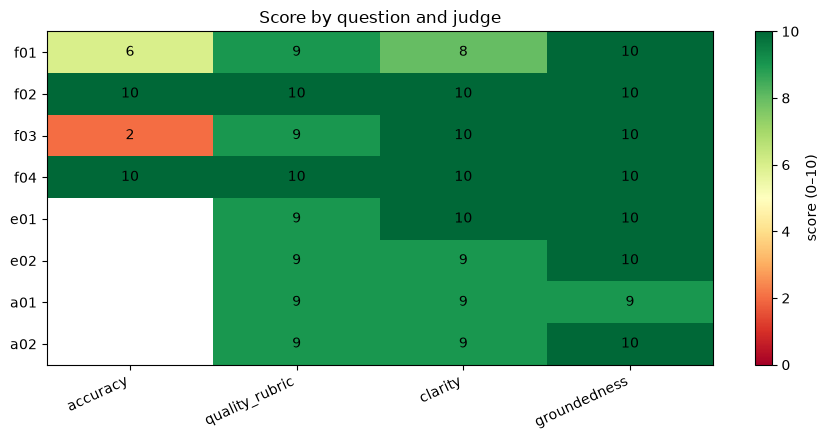

**Cases to inspect first**

| id | type | accuracy | quality_rubric | clarity | groundedness | disagreement |
| --- | --- | --- | --- | --- | --- | --- |
| f03 | factual | 2.0 | 9 | 10 | 10 | 8.0 |
| f01 | factual | 6.0 | 9 | 8 | 10 | 4.0 |
| e01 | explanatory | nan | 9 | 10 | 10 | 1.0 |
| e02 | explanatory | nan | 9 | 9 | 10 | 1.0 |
| a02 | advisory | nan | 9 | 9 | 10 | 1.0 |
| f02 | factual | 10.0 | 10 | 10 | 10 | 0.0 |
| f04 | factual | 10.0 | 10 | 10 | 10 | 0.0 |
| a01 | advisory | nan | 9 | 9 | 9 | 0.0 |

In [8]:
import matplotlib.pyplot as plt
import numpy as np

judge_cols = [judge.name for judge in JUDGES]
matrix = df.set_index("id")[judge_cols].astype(float)

fig, ax = plt.subplots(figsize=(9, 4.5))
image = ax.imshow(matrix.to_numpy(), vmin=0, vmax=10, cmap="RdYlGn", aspect="auto")
ax.set_xticks(range(len(judge_cols)), judge_cols, rotation=25, ha="right")
ax.set_yticks(range(len(matrix.index)), matrix.index)
ax.set_title("Score by question and judge")
for i in range(matrix.shape[0]):
    for j in range(matrix.shape[1]):
        value = matrix.iat[i, j]
        if not np.isnan(value):
            ax.text(j, i, f"{value:.0f}", ha="center", va="center", color="black")
fig.colorbar(image, ax=ax, label="score (0–10)")
plt.tight_layout()
plt.show()

df["disagreement"] = df[judge_cols].max(axis=1, skipna=True) - df[judge_cols].min(axis=1, skipna=True)
disagreement = df[["id", "type", *judge_cols, "disagreement"]].sort_values(
    "disagreement", ascending=False
)
ui.table(disagreement.to_dict("records"), title="Cases to inspect first")


## How to interpret the result

- **Accuracy** checks agreement with a reviewed factual answer. It still reflects an LLM judgment; use a programmatic comparison when the answer can be checked exactly.
- **Quality** checks usefulness and presentation against a rubric. It can reward fluent unsupported details.
- **Clarity** checks readability only.
- **Groundedness** checks claims against the supplied source, but it does not establish that the source itself is complete or correct.

If two scores differ, read their rationales and the original answer. Judge disagreement can reveal a response problem, an ambiguous rubric, or ordinary model variation.


## Task 8 — Audit the hardest case

Inspect the row with the largest score spread, including every rationale. Then test groundedness with a deliberately fabricated answer. The expected behavior is a low fabricated score; if it scores well, the evaluator—not the assistant—is the first thing to debug.


In [9]:
hardest_id = disagreement.iloc[0]["id"]
hardest = next(record for record in records if record["id"] == hardest_id)

print(f"Largest score spread: {hardest_id}\n")
print(hardest["question"])
print("\nRESPONSE\n", hardest["response"])
for name, result in hardest["judges"].items():
    print(f"\n{name}: {result['score']} — {result['rationale']}")

fabricated = {
    "id": "x01",
    "type": "factual",
    "question": "What is the maximum fine under the EU AI Act, and does it ban chatbots?",
    "reference": "Up to €35M or 7% of turnover; chatbots are disclosed, not banned.",
    "response": "The EU AI Act bans all chatbots and imposes fines of up to €500 million.",
}

print("\nFabricated answer:", groundedness(fabricated))
print("Dataset answer:   ", groundedness(runs[0]))


Largest score spread: f03

Which EU body supervises general-purpose AI models under the Act?

RESPONSE
 The summary doesn't specify a single supervisor for general-purpose models. Enforcement and oversight are shared between the new European AI Office, an AI Board, national competent authorities, and notified bodies.

accuracy: 2 — The candidate partially overlaps by mentioning the European AI Office but contradicts the reviewed answer by asserting there is no single supervisor and instead lists multiple bodies sharing oversight.

quality_rubric: 9 — Directly answers that there is no single supervisor, clearly lists the relevant coordinating bodies and authorities, and is concise and understandable.

clarity: 10 — The response is concise and unambiguous on first reading, clearly listing the European AI Office, the AI Board, national competent authorities, and notified bodies as the entities sharing supervision.

groundedness: 10 — The response accurately mirrors the summary, which stat

## Where this prototype stops

This notebook makes the mechanics visible, but its scores are not automatically client-ready.

| Prototype choice | What to add before relying on it |
|---|---|
| Eight curated questions | Broader coverage, reviewed labels, and difficult boundary cases |
| One or two model roles | Human calibration and checks for self-preference |
| Three repeat scores on one case | Repeatability estimates on a representative sample |
| Sequential calls | Concurrency, caching, retry policy, and rate-limit handling |
| Local JSONL | Versioned datasets, prompt/model metadata, and experiment tracking |
| Visual inspection | Release thresholds based on calibrated metrics |

### Useful extensions

1. Have a person score ten answers, then compare each judge with those ratings.
2. Evaluate the same answers with a different `JUDGE_MODEL`.
3. Track latency, token usage, and estimated cost alongside quality.
4. Add exact programmatic checks for dates, article numbers, and monetary amounts.
